# Исследовательский анализ жалоб CFPB

## Ключевой вопрос

В чем причина изменения количества жалоб в первом квартале 2025 года по сравнению с первым кварталом 2024 года?

## Исследовательские вопросы

1. Как изменилось количество жалоб между первым кварталом 2024 и первым кварталом 2025?
2. Как различается соотношение продуктов?
3. Как различается соотношение по проблемам?
4. Какова доля своевременных ответов?
5. Какие компании сформировали основной прирост жалоб??
6. Как распределено время передачи жалобы компании?
7. **Чем объясняется необычный объём жалоб в январе 2025 года?**

#### Ограничения

База CFPB не является полностью репрезентативной выборкой
всех клиентов финансовых организаций.

Количество жалоб нельзя напрямую интерпретировать как качество
компании или продукта без информации о размере клиентской базы
и рыночной доле.

In [50]:
from pathlib import Path
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [51]:
CURRENT_DIR=Path.cwd()
PROJECT_ROOT=(
    CURRENT_DIR.parent
    if CURRENT_DIR.name=="notebooks"
    else CURRENT_DIR
)
DATA_PATH = (PROJECT_ROOT /"data"/"processed"/"complaints_clean.pkl")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Файл не найден: {DATA_PATH}")
FIGURES_DIR = (PROJECT_ROOT/"reports"/"figures")
FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)
df=pd.read_pickle(DATA_PATH)
print("Размер таблицы:", df.shape)  # ожидаемый результат: (141822, 21)

Размер таблицы: (141822, 21)


#### Подключение DuckDB

Будем работать с SQL-запросами для агрегации данных

In [52]:
sql_df = df.drop(
    columns=["year_month"],
    errors="ignore"
).copy()
connection = duckdb.connect(database=":memory:")
connection.register("complaints", sql_df)

## Аналитические вопросы

#### Как изменилось количество жалоб между первым кварталом 2024 и первым кварталом 2025?

Сначала сравним кварталы целиком, чтобы увидеть картину в общем

In [53]:
yearly_counts=connection.sql(
    """
    SELECT year,
        COUNT(*) AS complaint_count
    FROM complaints
    GROUP BY year
    ORDER BY year
    """
).df()
yearly_counts

,year,complaint_count
0,2024,32489
1,2025,109333


Наблюдается значительное преобладание 2025 года в количестве жалоб.

Для точности, рассчитаем абсолютное и относительное изменение

In [54]:
counts=yearly_counts.set_index("year")["complaint_count"]
counts_2024=counts.loc[2024]
counts_2025=counts.loc[2025]
absolute_change=counts_2025 - counts_2024
percent_change=absolute_change/counts_2024 * 100
print("Абсолютное изменение:", absolute_change)
print(f"Относительное изменение:{round(percent_change, 2)} %")

Абсолютное изменение: 76844
Изменение:236.52 %


**Наблюдение**

В первом квартале 2025 года зарегистрировано 109 333 жалобы против 32 489 в первом квартале 2024 года. Абсолютный прирост составил 76 844 обращения, относительный — 236,52%. Таким образом, количество жалоб увеличилось более чем втрое.

Для формирования наиболее ясного понимания, рассмотрим динамику по месяцам внутри кварталов

Для большей наглядности визуализируем ее с помощью графика

In [55]:
yearly_counts=connection.sql(
    """
    SELECT year,
        month,
        COUNT(*) AS complaint_count
    FROM complaints
    GROUP BY year, month
    ORDER BY year, month
    """
).df()
yearly_counts

,year,month,complaint_count
0,2024,1,10565
1,2024,2,10321
2,2024,3,11603
3,2025,1,77183
4,2025,2,17793
5,2025,3,14357


Рассмотрим динамику по месяцам, чтобы понять, как росли обращения

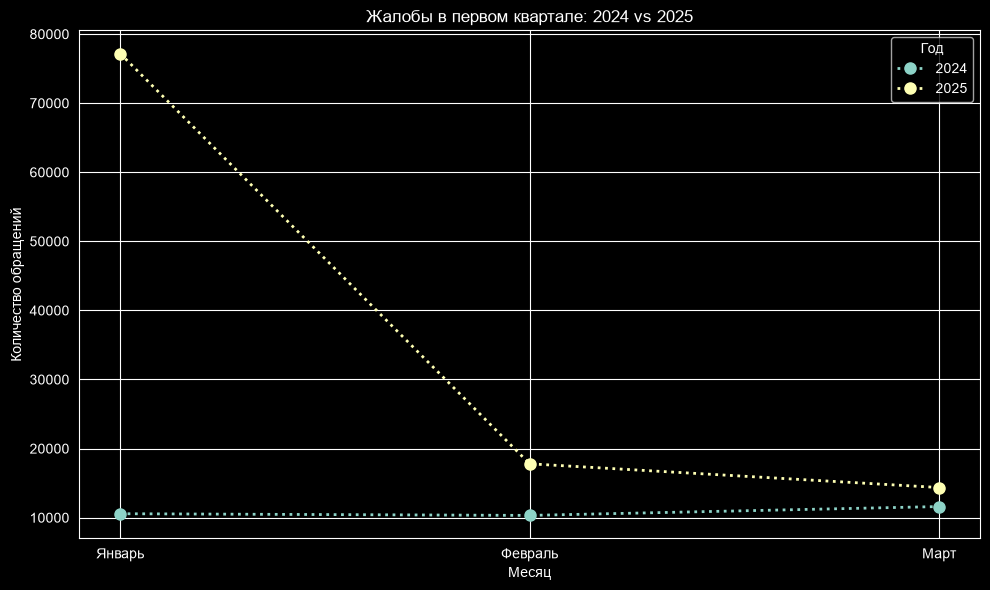

In [104]:
fig, ax=plt.subplots(figsize=(10, 6))
for year, grp in yearly_counts.groupby("year"):
    grp=grp.sort_values("month")
    ax.plot(
        grp["month"],
        grp["complaint_count"],
        marker="o",
        linewidth=2,
        markersize=8,
        linestyle=":",
        label=str(year)
    )
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(["Январь", "Февраль", "Март"])
ax.set_xlabel("Месяц")
ax.set_ylabel("Количество обращений")
ax.set_title("Жалобы в первом квартале: 2024 vs 2025")
ax.legend(title="Год")
plt.tight_layout()
plt.show()


Наблюдения:
- В январе 2025 года количество обращений было аномальным, оно значительно превышало как показатели за январь прошлого года, так и количество обращений за следующие месяцы квартала
- Количество обращений по каждому месяцу первого квартала 2025 года повышает аналогичные значения для 2024 года
- Среди месяцев первого квартала 2024 года значения почти не изменяются

#### Как различается соотношение продуктов?

In [57]:
monthly_counts=connection.sql(
    """
    SELECT year,
        product,
        COUNT(*) AS complaint_count,
        COUNT(*) * 100.0 / SUM(COUNT(*)) OVER(PARTITION BY year) AS complaint_percentage
    FROM complaints
    GROUP BY year, product
    ORDER BY year
    """
).df()
monthly_counts

,year,product,complaint_count,complaint_percentage
0,2024,Credit card,16318,50.226230
1,2024,Checking or savings account,12122,37.311090
2,2024,"Money transfer, virtual currency, or money ser...",4049,12.462680
3,2025,"Money transfer, virtual currency, or money ser...",58903,53.874859
4,2025,Checking or savings account,28889,26.422946
5,2025,Credit card,21541,19.702194


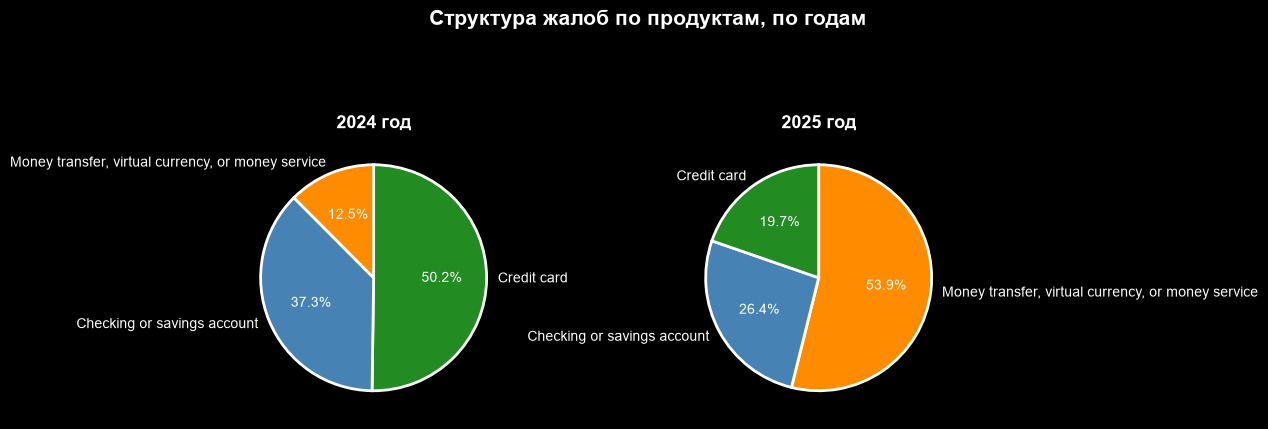

In [107]:
years=sorted(monthly_counts["year"].unique())
color_map={
    "Credit card": "#228B22",
    "Checking or savings account": "#4682B4",
    "Money transfer, virtual currency, or money service": "#FF8C00"}
fig, axes = plt.subplots(1, len(years), figsize=(6 * len(years), 5))

for ax, y in zip(axes, years):
    sub = (monthly_counts[monthly_counts["year"] == y].sort_values("complaint_count", ascending=False))
    pie_colors=[color_map[x] for x in sub["product"]]
    ax.pie(
        sub["complaint_count"],
        labels=sub["product"],
        autopct="%1.1f%%",
        startangle=90,
        counterclock=False,
        colors=pie_colors,
        wedgeprops=dict(edgecolor="white", linewidth=2),
    )
    ax.set_title(f"{y} год", fontsize=13, fontweight="bold")
fig.suptitle("Структура жалоб по продуктам, по годам", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

**Наблюдения**

- Значительно выросла доля жалоб на денежные переводы, виртуальную валюту или денежные сервисы(`Money transfer, virtual currency, or money service`), рост составил 41.4 процентных пунктов
- Значительно сократилась доля жалоб, связанных с кредитными картами(`Credit card`): доля уменьшилась с 50.2% до 19.7% т.е. на 30.5 процентных пунктов
- Сокращение жалоб по поводу счета(`Checking or savings account`) составляет 10.9 процентных пунктов

**Интерпретация**

Структура жалоб сильно изменилась, но стоит учитывать, что абсолютное количество жалоб выросло по всем трём продуктам. Особенно требует рассмотрения категория денежных переводов, поскольку она выросла настолько сильнее других анализируемых продуктов, что заняла большую часть всей выборки7 Именно из-за такого роста `Money transfer, virtual currency, or money service` доли жалоб по кредитным картам и банковским счетам сократились, при росте абсолютного значения

**Гипотеза**

Резкий рост категории денежных переводов, виртуальной валюты и денежных сервисов (`Money transfer, virtual currency, or money service`) в первого квартале 2025 года распределен неравномерно и сконцентрирован в определенной подкатегории жалоб и компаний. Рассмотрим соотношение `issue`, вклад отдельных компаний и помесячную динамику жалоб.

#### Как различается соотношение по проблемам?

In [59]:
issue_structure = connection.sql(
    """
    WITH issue_counts AS (
        SELECT year,
            product,
            issue,
            COUNT(*) AS issue_count
        FROM complaints
        WHERE issue IS NOT NULL
        GROUP BY year, product, issue
    )
    SELECT year,
        product,
        issue,
        issue_count,
        ROUND(100.0 * issue_count/SUM(issue_count) OVER (PARTITION BY year, product), 2) AS issue_percent
    FROM issue_counts
    ORDER BY product,
        year,
        issue_count DESC
    """
).df()

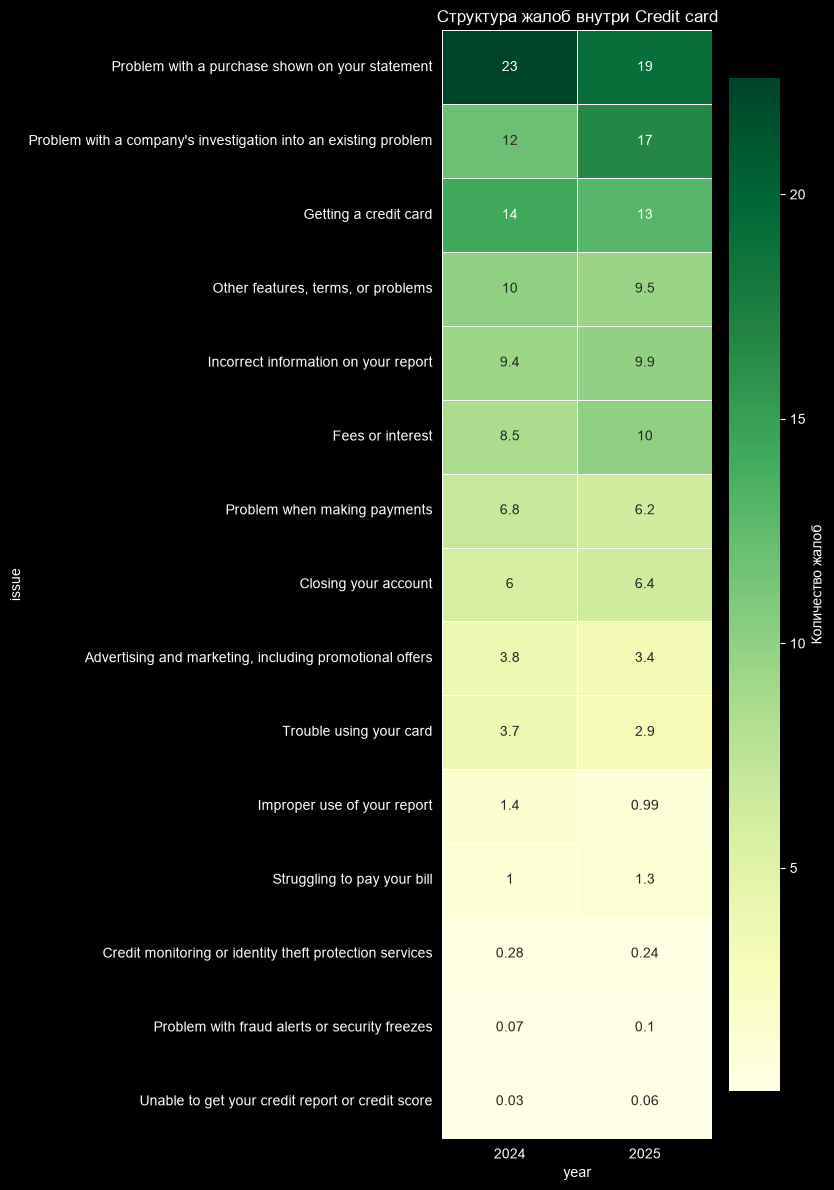

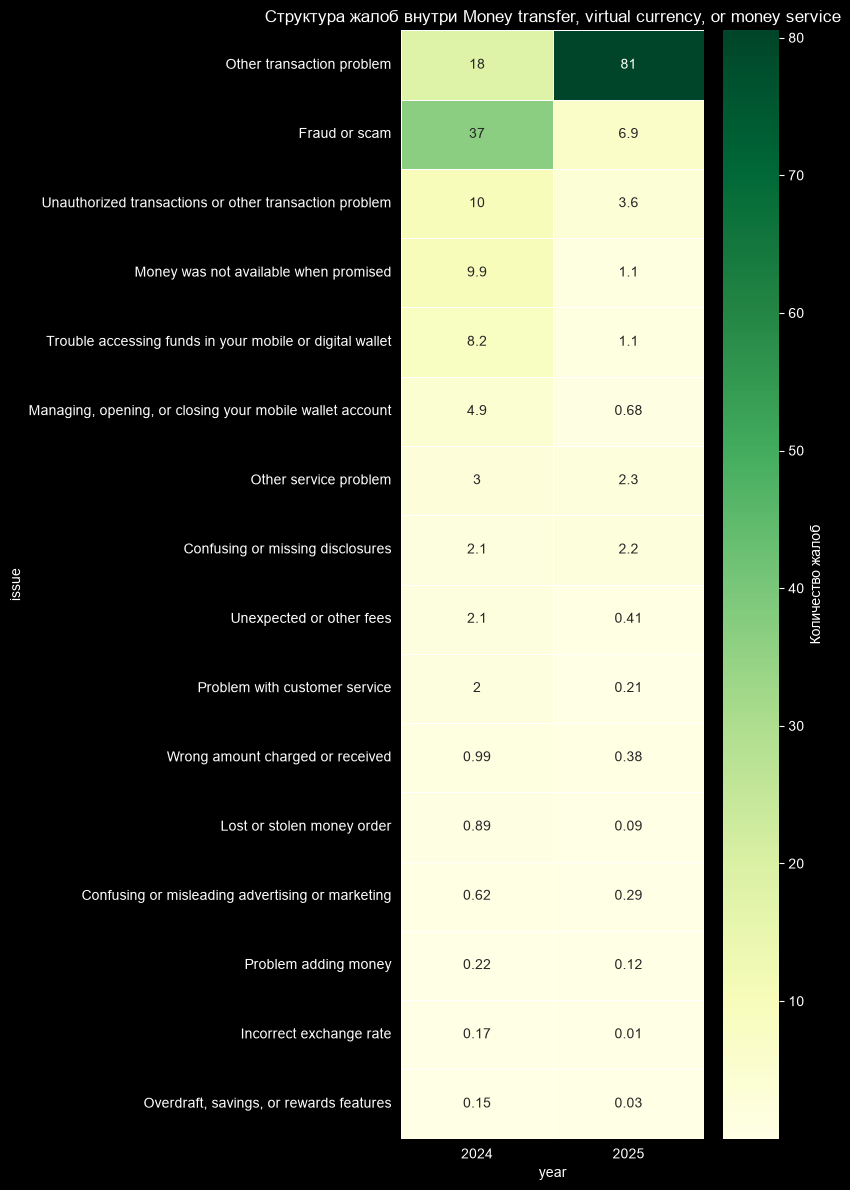

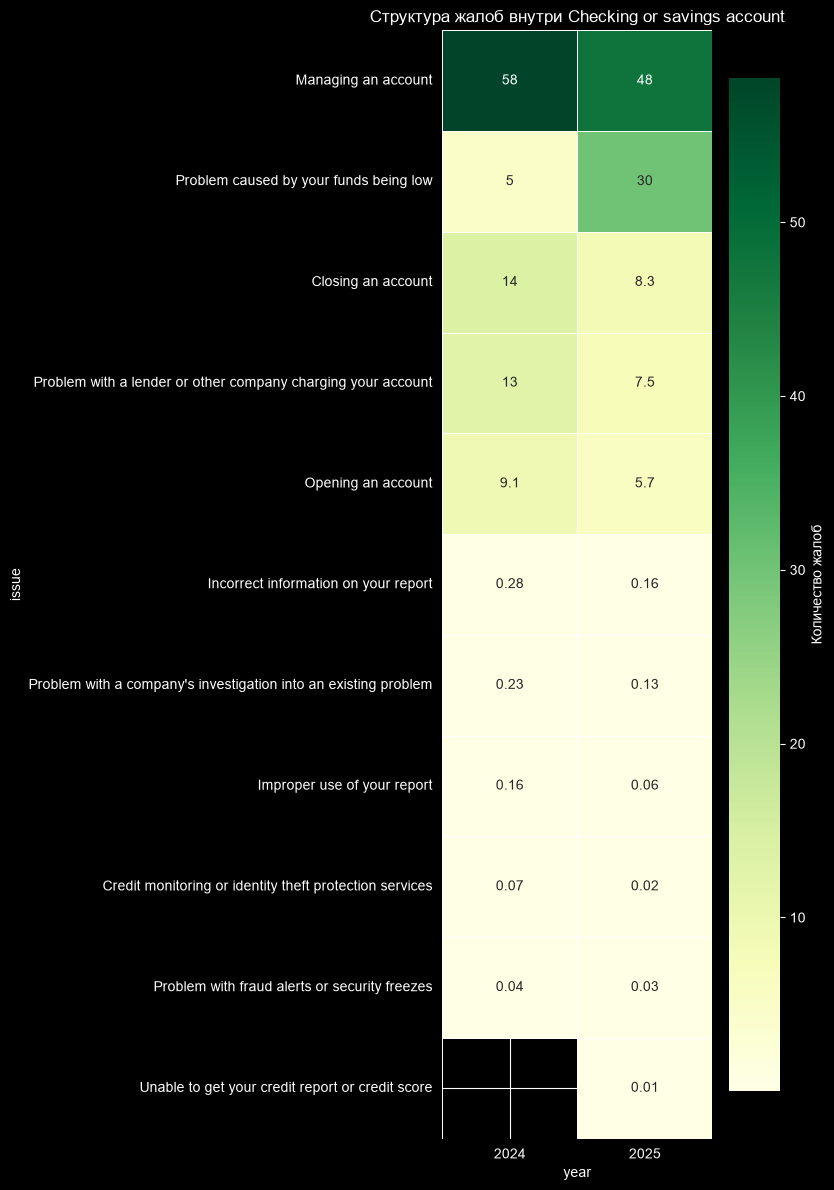

In [142]:
products=set(issue_structure["product"])
for product in products:
    product_data = issue_structure[issue_structure["product"]==product]
    pivot=(product_data.pivot_table(index="issue", columns="year", values="issue_percent"))
    top_issues = pivot.sum(axis=1).nlargest(20).index
    pivot = pivot.loc[top_issues]
    fig, ax = plt.subplots(figsize=(8, 12))
    sns.heatmap(
        pivot, annot=True, cmap="YlGn",
        linewidths=0.5, linecolor="white",
        cbar_kws={"label": "Количество жалоб"}, ax=ax)
    ax.set_title(f"Структура жалоб внутри {product}")
    plt.tight_layout()
    plt.show()


##### **Наблюдение**

**Checking or savings account**

- Доля Managing an account снизилась с 58,29% в 2024 году до 47,90% в 2025 году. При этом абсолютное количество жалоб выросло с 7 066 до 13 839.
- Доля Problem caused by your funds being low повысилась с 5% до 30,19%, а количество жалоб выросло с 606 до 8 721.
- Несмотря на снижение доли, Managing an account осталась наиболее распространённой проблемой внутри продукта.

**Money transfer, virtual currency, or money service**

- **Доля Other transaction problem выросла с 18,00% до 80,52%, а абсолютное количество жалоб — с 729 до 47 430**
- Other transaction problem стала доминирующей проблемой внутри продукта в 2025 году.
- Доля Fraud or scam снизилась с 36,65% до 6,91%.
- Доля Unauthorized transactions or other transaction problem снизилась с 9,98% до 3,63%

**Credit card**

- Доля Problem with a purchase shown on your statement снизилась с 22,59% до 19,14%.
- Доля Getting a credit card незначительно снизилась с 14,33% до 12,99%.
- Доля Fees or interest выросла с 8,54% до 10,06%.
- выросла доля Problem with a company's investigation into an existing problem: с 11,89% до 16,74%.

**Интерпретация**

- Структура проблем внутри категории Credit card оставалась относительно стабильной: Problem with a purchase shown on your statement сохранила первое место, хотя её доля немного снизилась
- Managing an account осталась основной проблемой в категории Checking or savings account, однако её относительная доля снизилась. Одновременно резко выросла доля Problem caused by your funds being low, связанная с недостатком средств, овердрафтом и соответствующими комиссиями.
- **В категории Money transfer, virtual currency, or money service произошёл резкий структурный сдвиг: Other transaction problem стала доминирующей проблемой и заняла более 80% обращений.**

В категории Other transaction problem наблюдается наибольший рост, а в самой категории Money transfer, virtual currency, or money service структура изменилась сильнее всего, поэтому детально изучим именно эту тенденцию

**Описание категории Other transaction problem**

- Несанкционированная транзакция

     Клиент утверждает, что не совершал или не разрешал перевод
- Проблема с отменой транзакции

     Перевод не удалось отменить либо отмена была обработана неправильно;
- Проблема с возвратом денег

     Возврат не поступил, задержался или был обработан некорректно.

Посмотрим, можем ли мы оценить структуру `sub_issue`

In [126]:
sub_issue_counts=connection.sql(
    """
    SELECT issue,
        sub_issue
    FROM complaints
    WHERE issue='Other transaction problem'
    GROUP BY issue,
        sub_issue
"""
)
sub_issue_counts

┌───────────────────────────┬───────────┐
│           issue           │ sub_issue │
│          varchar          │  varchar  │
├───────────────────────────┼───────────┤
│ Other transaction problem │ NULL      │
└───────────────────────────┴───────────┘

**Наблюдение и интерпретация**

Для всех жалоб с issue = "Other transaction problem" поле sub_issue не заполнено. Поэтому структурированные данные не позволяют разделить обращения на несанкционированные транзакции, проблемы с отменой и проблемы с возвратом средств.

**Гипотеза**

Рост Other transaction problem в 2025 году распределён неравномерно и сконцентрирован в определённом месяце и ограниченном количестве компаний.


In [129]:
other_transaction_monthly = connection.sql(
    """
    SELECT year,
        month,
        COUNT(*) AS complaint_count
    FROM complaints
    WHERE issue = 'Other transaction problem'
    GROUP BY year, month
    ORDER BY year, month
    """
).df()

other_transaction_monthly

,year,month,complaint_count
0,2024,1,226
1,2024,2,227
2,2024,3,276
3,2025,1,42521
4,2025,2,3720
5,2025,3,1189


**Наблюдение**

Количество жалоб Other transaction problem действительно не распределено равномерно и большинство сообщений приходится на январь 2025 года

Оценим ежедневную динамику внутри пикового месяца

In [143]:
other_transaction_daily = connection.sql(
    """
    SELECT CAST(date_received AS DATE) AS received_date,
        COUNT(*) AS complaint_count
    FROM complaints
    WHERE issue = 'Other transaction problem'
      AND date_received >= '2025-01-01'
      AND date_received < '2025-02-01'
    GROUP BY received_date
    ORDER BY received_date
    """
).df()

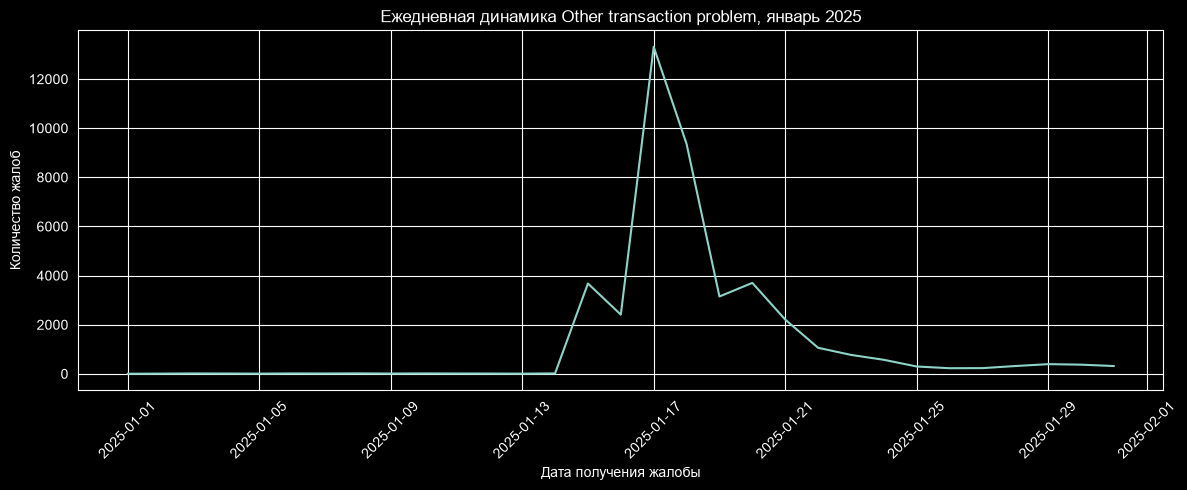

In [132]:
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=other_transaction_daily,
    x="received_date",
    y="complaint_count"
)
plt.title('Ежедневная динамика "Other transaction problem" за январь 2025')
plt.xlabel("Дата получения жалобы")
plt.ylabel("Количество жалоб")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Наблюдение**

Максимум был зафиксирован 17 января 2025 года — 13 445 обращений. На 17 и 18 января вместе пришлось более половины всех январских жалоб этой категории.

#### Какова доля своевременных ответов?

In [133]:
answers_timely=connection.sql(
    """
     SELECT year,
        month,
        ROUND(COUNT(*) FILTER (WHERE is_timely) * 100.0 / COUNT(*), 2) AS percent_timely_answer
    FROM complaints
    GROUP BY year, month
    ORDER BY year, month
    """
).df()
answers_timely

,year,month,percent_timely_answer
0,2024,1,99.46
1,2024,2,99.36
2,2024,3,99.07
3,2025,1,99.80
4,2025,2,99.41
5,2025,3,99.37


**Наблюдение**

- В каждом месяце доля не пришедших вовремя ответов очень маленькая
- Разброс процента вовремя пришедших ответов крайне мал: минимум в марте 2024 года-99.07% и максимум в январе 2025 года-99.80% т.е. разница составляет 0.73 п.п.


#### Какие компании выделяются в данных?

Рассмотрим кто является лидером по жалобам

In [145]:
company_growth = connection.sql(
    """
    WITH company_counts AS (
        SELECT company,
            COUNT(*) FILTER (WHERE year=2024) AS complaints_2024,
            COUNT(*) FILTER (WHERE year=2025) AS complaints_2025
        FROM complaints
        GROUP BY company
    )
    SELECT company,
        complaints_2024,
        complaints_2025,
        complaints_2025-complaints_2024 AS absolute_growth
    FROM company_counts
    ORDER BY absolute_growth DESC
    """
).df()
company_growth


,company,complaints_2024,complaints_2025,absolute_growth
0,"Block, Inc.",657,36469,35812
1,"Early Warning Services, LLC",142,18351,18209
2,NAVY FEDERAL CREDIT UNION,760,8894,8134
3,CAPITAL ONE FINANCIAL CORPORATION,2378,7859,5481
4,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",1098,2092,994
...,...,...,...,...
627,ALLY FINANCIAL INC.,280,238,-42
628,Sigue Corp.,55,6,-49
629,"Credit Karma, LLC",217,146,-71
630,BMO BANK NATIONAL ASSOCIATION,289,186,-103


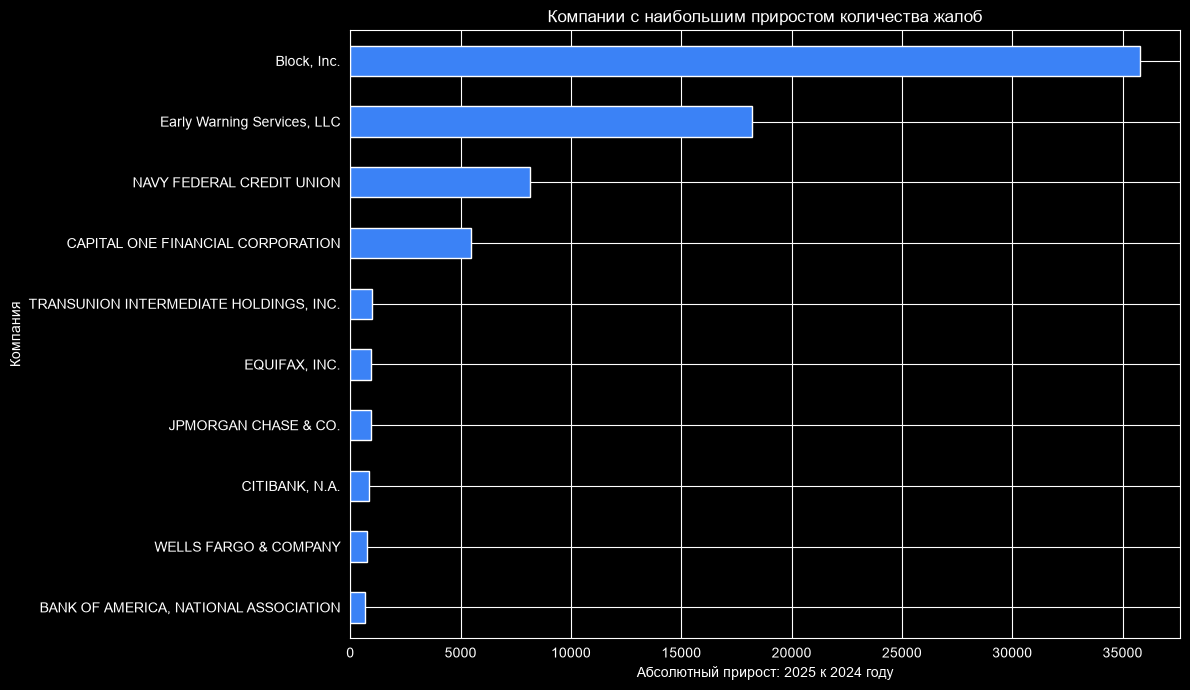

In [147]:
top_company_growth=(company_growth.nlargest(10, "absolute_growth").sort_values("absolute_growth"))
ax = top_company_growth.plot(
    kind="barh",
    x="company",
    y="absolute_growth",
    figsize=(12, 7),
    legend=False,
    color="#3B82F6")
ax.set_title("Компании с наибольшим приростом количества жалоб")
ax.set_xlabel("Абсолютный прирост: 2025 к 2024 году")
ax.set_ylabel("Компания")
plt.tight_layout()
plt.show()


**Наблюдение**

- По объему прироста выделяется 4 компании:  Block, Inc; Early Warning Services, LLC; NAVY FEDERAL CREDIT UNION; CAPITAL ONE FINANCIAL CORPORATION
- Среди представленных десяти компаний-лидеров по приросту можно заметить, что Block, Inc значительно превосходит все остальные компании по приросту жалоб: прирост Early Warning Services практически в 2 раза меньше чем у Block, при том, что Early Warning Services занимает второе место по приросту жалоб.


**Интерпретация**

Рост количества жалоб не был равномерным по финансовому рынку, а оказался сконцентрирован у ограниченного количества компаний. Почти половина общего прироста связана с Block, а Block и Early Warning Services вместе сформировали более 70% увеличения. Это означает, что необычная динамика первого квартала 2025 года, вероятно, отражает изменения в обращениях по конкретным сервисам и компаниям, а не общее ухудшение по всем участникам рынка.

**Гипотеза**

Основная часть прироста жалоб у Block и Early Warning Services связана с продуктом Money transfer, virtual currency, or money service, проблемой Other transaction problem и приходится на январь 2025 года. Для проверки необходимо сравнить структуру продуктов и проблем внутри этих компаний, а затем изучить помесячную и ежедневную динамику обращений.

Изучим структуру жалоб конкретно этих двух компаний

In [150]:
company_issue_structure = connection.sql(
    """
    WITH issue_counts AS (
        SELECT company,
            year,
            issue,
            COUNT(*) AS complaint_count
        FROM complaints
        WHERE company IN ('Block, Inc.','Early Warning Services, LLC')
          AND product = ('Money transfer, virtual currency, or money service')
          AND issue IS NOT NULL
        GROUP BY company, year, issue
    )
    SELECT company,
        year,
        issue,
        complaint_count,
        ROUND(100.0*complaint_count/SUM(complaint_count) OVER (PARTITION BY company, year), 2) AS issue_share_percent
    FROM issue_counts
    ORDER BY company, year, complaint_count DESC
    """
).df()

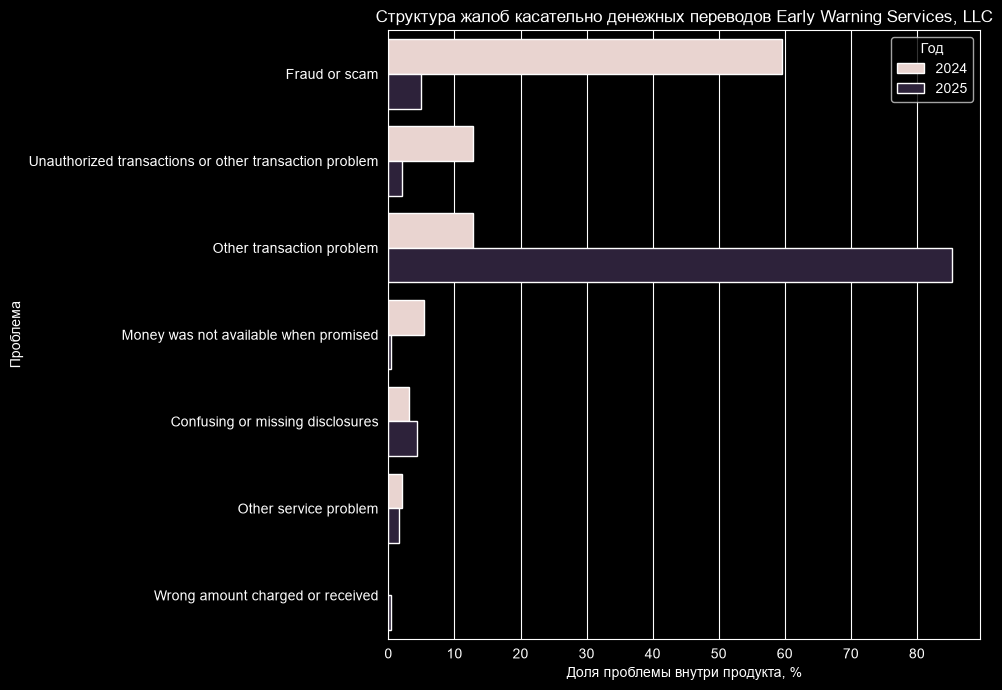

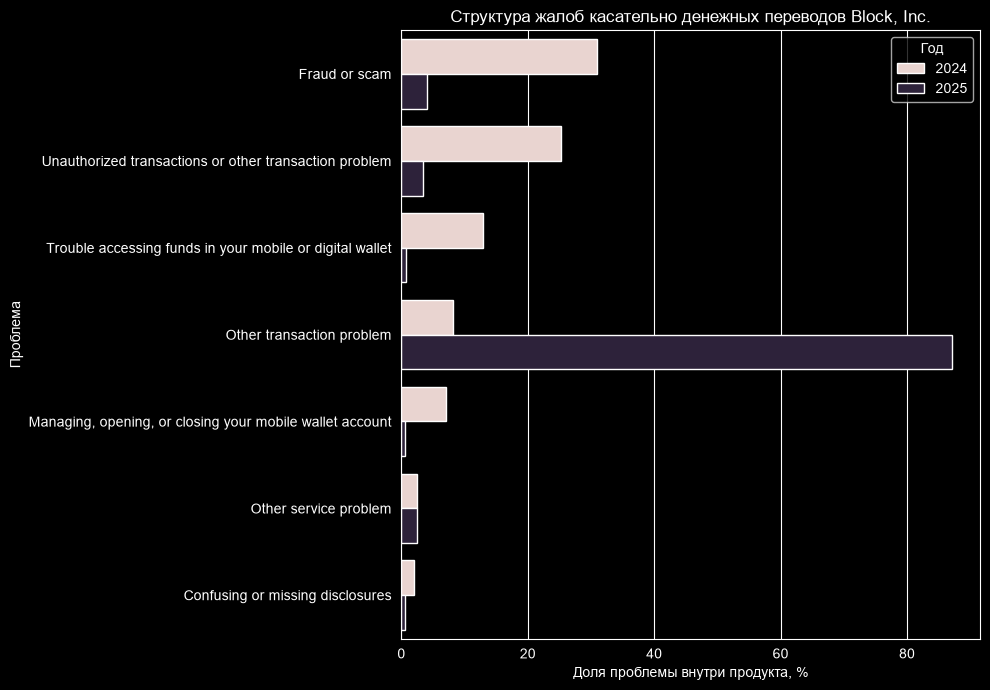

In [151]:
companies=(	"Early Warning Services, LLC", "Block, Inc." )
for company in companies:
    company_data = company_issue_structure[company_issue_structure["company"]==company]
    top_issues = (company_data.groupby("issue")
                  ["complaint_count"].sum().nlargest(7).index)
    plot_data = company_data[company_data["issue"].isin(top_issues)]
    fig, ax = plt.subplots(figsize=(10, 7))
    sns.barplot(
        data=plot_data,
        x="issue_share_percent",
        y="issue",
        hue="year",
        ax=ax
    )
    ax.set_title(f"Структура жалоб касательно денежных переводов {company}")
    ax.set_xlabel("Доля проблемы внутри продукта, %")
    ax.set_ylabel("Проблема")
    ax.legend(title="Год")
    plt.tight_layout()
    plt.show()

**Наблюдение**

В 2025 году структура жалоб на денежные переводы резко изменилась у обеих компаний. Other transaction problem составила 87,18% жалоб на денежные переводы у Block и 85,28% у Early Warning Services.

Рассмотрим в каком месяце произошел рост жалоб в этой категории у Block и Warning Services

In [157]:
monthly_block_EWS=connection.sql(
    """
     SELECT company,
        year,
        month,
        COUNT(*) AS complaint_count
    FROM complaints
    WHERE issue = 'Other transaction problem'
        AND company IN ('Block, Inc.','Early Warning Services, LLC')
    GROUP BY company, year, month
    ORDER BY complaint_count DESC
    """
).df()
monthly_block_EWS

,company,year,month,complaint_count
0,"Block, Inc.",2025,1,27659
1,"Early Warning Services, LLC",2025,1,14159
2,"Block, Inc.",2025,2,2299
3,"Early Warning Services, LLC",2025,2,1133
4,"Block, Inc.",2025,3,785
5,"Early Warning Services, LLC",2025,3,107
6,"Block, Inc.",2024,3,15
7,"Block, Inc.",2024,1,11
8,"Block, Inc.",2024,2,11
9,"Early Warning Services, LLC",2024,1,4


**Наблюдение**

- у обеих компаний рост Other transaction problem сосредоточен преимущественно в январе 2025 года.
- после января жалобы в категории значительно снижаются

**Интерпретация**

Рост не является равномерным трендом всего квартала.

Исследуем ежедневную динамику в январе для этих компаний

In [160]:
other_transaction_daily_block_EWS = connection.sql(
    """
    SELECT company,
        CAST(date_received AS DATE) AS received_date,
        COUNT(*) AS complaint_count
    FROM complaints
    WHERE issue = 'Other transaction problem'
      AND date_received >= '2025-01-01'
      AND date_received < '2025-02-01'
      AND company IN ('Block, Inc.','Early Warning Services, LLC')
    GROUP BY company, received_date
    ORDER BY received_date
    """
).df()

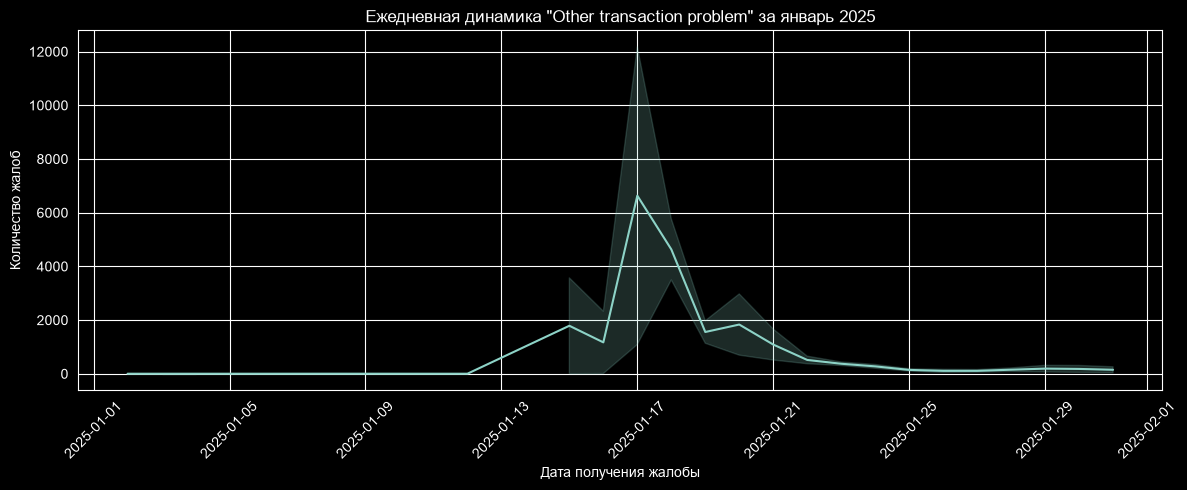

In [161]:
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=other_transaction_daily_block_EWS,
    x="received_date",
    y="complaint_count"
)
plt.title('Ежедневная динамика "Other transaction problem" за январь 2025')
plt.xlabel("Дата получения жалобы")
plt.ylabel("Количество жалоб")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Наблюдение**

Жалобы обеих компаний сконцентрированы в коротком периоде с 15 по 21 января, а максимум приходится на 17 января.

**Интерпретация**

Январский рост был сформирован не только небольшим количеством компаний и одной проблемой, но и очень узким временным интервалом.

#### Как распределено время передачи жалобы компании?

Показатель `hours_to_send` отражает фактическое количество часов между
получением жалобы CFPB и её передачей компании.

Для описания типичного времени используются медиана и 75-й процентиль.
90-й и 99-й процентили позволяют исследовать редкие длительные задержки.

Дополнительно жалобы распределяются по временным интервалам, после чего
сравниваются доли этих интервалов в первом квартале 2024 и 2025 годов.

Показатель характеризует скорость передачи жалобы ведомством CFPB,
а не скорость ответа самой компании.

In [76]:
transfer_data = df.loc[
    df["hours_to_send"].notna()
    & (df["hours_to_send"]>=0)
]
transfer_distribution = (
    transfer_data.groupby(["year", "product"], as_index=False)
    .agg(
        complaint_count=("hours_to_send", "size"),
        mean_hours=("hours_to_send", "mean"),
        median_hours=("hours_to_send", lambda x: x.median()),
        p75_hours=("hours_to_send", lambda x: x.quantile(0.75)),
        p90_hours=("hours_to_send", lambda x: x.quantile(0.90)),
        p99_hours=("hours_to_send", lambda x: x.quantile(0.99)),
        over_24_hours_percent=("hours_to_send", lambda x: x.gt(24).mean()*100)
    ).round(2)
)
transfer_distribution

,year,product,complaint_count,mean_hours,median_hours,p75_hours,p90_hours,p99_hours,over_24_hours_percent
0,2024,Checking or savings account,12122,14.49,0.37,0.75,22.53,265.75,9.46
1,2024,Credit card,16318,13.02,0.27,0.56,2.96,215.23,7.84
2,2024,"Money transfer, virtual currency, or money ser...",4049,20.67,0.34,0.62,1.77,348.29,7.83
3,2025,Checking or savings account,28889,18.01,0.24,0.44,1.27,505.02,6.50
4,2025,Credit card,21541,33.85,0.23,0.54,40.17,887.29,10.63
5,2025,"Money transfer, virtual currency, or money ser...",58903,11.25,0.26,0.46,27.54,181.20,10.84


**Наблюдения**

- Для Checking or savings account доля жалоб, переданных более чем за 24 часа, снизилась с 9,46% до 6,50%.
- Для Credit card показатель вырос с 7,84% до 10,63%.
- Для Money transfer, virtual currency, or money service показатель вырос с 7,83% до 10,84%.
- 90-й процентиль для кредитных карт увеличился с 2,96 до 40,17 часа, а для денежных переводов — с 1,77 до 27,54 часа.

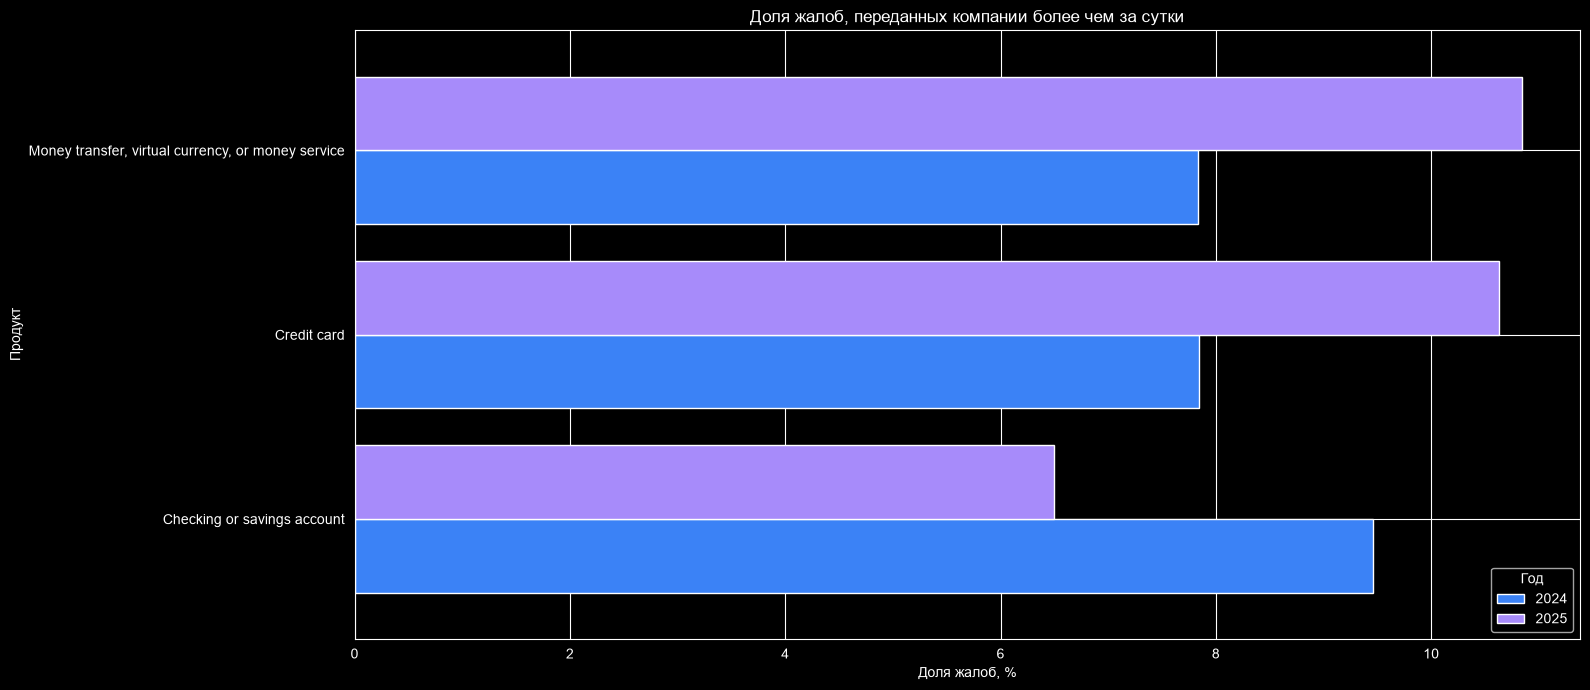

In [94]:
pivot_df=(transfer_distribution.pivot_table(
        index="product",
        columns="year",
        values="over_24_hours_percent",
        fill_value=0))
ax = pivot_df.plot(
    kind="barh",
    figsize=(16, 7),
    color=["#3B82F6", "#A78BFA"],
    width=0.8)
ax.set_title("Доля жалоб, переданных компании более чем за сутки")
ax.set_xlabel("Доля жалоб, %")
ax.set_ylabel("Продукт")
ax.legend(title="Год")
plt.tight_layout()
plt.show()

**Наблюдение и интерпретация**

Рост нагрузки не сопровождался ухудшением типичного времени передачи: медиана немного снизилась по всем продуктам. Однако у кредитных карт и денежных переводов увеличилась доля обращений, переданных более чем за сутки, а также вырос 90-й процентиль. Следовательно, типичные обращения передавались быстро, но среди наиболее долгих случаев задержки стали заметнее.

#### Чем объясняется необычный объём жалоб в январе 2025 года?

**Общие итоги по нашим наблюдениям:**

В первом квартале 2025 года количество жалоб выросло на 76 844 обращений, что можно оценить как рост 236.52% по сравнению с первым кварталом 2024 года.

Рост отказался неравномерным и большинство жалоб(77 183) были отправлены в январе 2025 года.

Основным источником изменения стала категория Money transfer, virtual currency, or money service, доля которой увеличилась с 12,46% до 53,87%. Внутри неё произошёл резкий рост Other transaction problem: количество таких жалоб увеличилось с 729 до 47 430, причём 42 521 обращение, или 89,7%, пришлось на январь 2025 года.

При этом рост сконцентрирован между двумя компаниями: Block и Early Warning Services. Они сформировали около 70% общего прироста всех жалоб, в период января на них пришлось 27 659(Block) и 14 159(EWS) жалоб с темой Other transaction problem. Вместе эти компании сформировали 98,35% январских жалоб рассматриваемой категории.

Ежедневная динамика показывает дополнительную концентрацию в периоде с 15 по 21 января. Максимум наблюдался 17 января.

Для наиболее точного ответа на поставленный вопрос пришлось воспользоваться внешними источниками
1. https://www.consumerfinance.gov/enforcement/actions/block-inc/
16 января 2025 года CFPB опубликовала решение в отношении Block, которая управляла платежным приложением Cash App. Регулятор установил, что в течение нескольких лет сервис систематически совершал нарушения, вредящие пользователям:
 - Отсутствие эффективной службы поддержки. Cash App отказывался создавать горячую линию, благодаря которой пользователь мог бы посоветоваться с реальным специалистом и решить свою проблему. Мошенники пользовались этим и создавали свою, фальшивую горячую линию, через которую они крали личные данные пользователей
  - Отсутствие мер противодействия мошенникам. Компания знала о том, что потребители становятся жертвами мошенников, однако не предпринимала никаких эффективных и своевременных шагов, направленных на борьбу с этим
  - Нарушение правил обработки споров. Компания использовала процедуру чарджбэка (возврата платежа через платёжную сеть) как замену своим прямым обязанностям по расследованию и разрешению споров о несанкционированных транзакциях, что является нарушением Закона об электронных переводах (EFTA) и Правила E
  - Обман потребителей. Компания заявляла, что защищает клиентов от несанкционированных переводов и имеет телефонную линию для сообщения о таких случаях, что не соответствовало действительности
В решении закрепляются санкции, которые накладываются на Block, Inc:
  - требуется создание инфраструктуру, защищающую пользователей от мошенников
  - компенсировать пострадавшим потребителям от 75 до 120 миллионов долларов
  - назначен гражданский штраф в размере 55 миллионов долларов
2. https://www.consumerfinance.gov/enforcement/actions/early-warning-services-llc-bank-of-america-na-jpmorgan-chase-bank-na-wells-fargo-bank-na/
20 декабря 2024 года CFPB подало в суд на компанию Early Warning Services (оператора платёжной системы Zelle) и банки-совладельцы — Bank of America, JPMorgan Chase и Wells Fargo.

Регулятор обвинял их по нескольким причинам:

  - Нарушение запрета на несправедливые действия в соответствии с Законом о защите прав потребителей финансовых услуг (CFPA). По мнению CFPB, компании не обеспечили должную защиту пользователей от мошенничества на платформе.
  - Нарушение законов о переводах: банки нарушили Закон об электронных переводах (EFTA) и его Правило E, что касается обработки споров и ошибок

**Итог**

Внешние события тематически и по времени совпадают с выявленным всплеском: подавляющее большинство январских жалоб Other transaction problem распределено между Block и Early Warning Services, а их пик пришёлся на середину января. Это позволяет предположить, что регуляторные действия и повышенное внимание потребителей повлияли на количество обращений. Однако совпадение не доказывает причинную связь, поэтому результаты следует интерпретировать как обоснованную гипотезу, а не установленную причину.